In [1]:
# CTD analysis: North Sea transect, 1993 - 2023, in steps of 5 years.
# This script loads the CTD results of every expedition year, and makes figures for temperature, oxygen, nitrate and chlorophyll (these were the sensors turned on for the CTD casts)
# uses the Cruise Coordinates which are predetermined for the students (Transect across the North Sea from Texel - Norway - Dutch Coastal Waters - TexeL).

# using the virtualship-postprocessing (from binder's environment.yml file) kernel to run this notebook, which has the necessary packages installed
from pathlib import Path

import cmocean.cm as cmo
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import parcels

In [2]:
# Folder that contains the year folders (1993, 1998, ...).
# Expected structure:  BASE_DIR/1993/results/ctd.parquet
BASE_DIR = Path("/Users/4926196/Downloads/VSC/Oceans of the Future_BSc UU/Expeditions")

YEARS = [1993, 1998, 2003, 2008, 2013, 2018, 2023]

# Time series use the mean over the top part of the water column (metres)
UPPER_DEPTH = 100

# Settings for the vertical profile figure
PROFILE_STATION = 1  # 1 = first CTD station (northernmost, deepest water)
PROFILE_MAX_DEPTH = None  # metres; set to None to show the full cast

In [3]:
# only using these sensors
VARIABLES = {
    "temperature": {
        "ds_name": "temperature",
        "label": "Temperature (°C)",
        "cmap": cmo.thermal,
    },
    "oxygen": {
        "ds_name": "o2",
        "label": r"Dissolved oxygen (mmol m$^{-3}$)",
        "cmap": cmo.oxy,
    },
    "nitrate": {
        "ds_name": "no3",
        "label": r"Nitrate (mmol m$^{-3}$)",
        "cmap": cmo.matter,
    },
    "chlorophyll": {
        "ds_name": "chl",
        "label": r"Chlorophyll (mg m$^{-3}$)",
        "cmap": cmo.algae,
    },
}
VAR_NAMES = list(VARIABLES)

In [7]:
# loading all years into one table
def load_year(year):
    """Read ctd.parquet of one year and return a tidy table (downcast only)."""
    path = BASE_DIR / str(year) / "results" / "ctd.parquet"
    if parcels is not None:
        df = parcels.read_particlefile(str(path))
    else:
        df = pl.read_parquet(path)

    # check that all columns are present
    needed = ["particle_id", "x", "y", "z"] + [v["ds_name"] for v in VARIABLES.values()]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(
            f"{path} is missing columns {missing}. Available: {df.columns}"
        )

    # downcast only (the CTD going down, as in the sample notebook)
    if "raising" in df.columns:
        df = df.filter(pl.col("raising") == 0)

    # number the stations in the order they were sampled
    order_col = "time" if "time" in df.columns else "particle_id"
    stations = (
        df.group_by("particle_id")
        .agg(
            pl.col("x").mean().alias("lon"),
            pl.col("y").mean().alias("lat"),
            pl.col(order_col).min().alias("t0"),
        )
        .sort("t0")
        .with_columns((pl.int_range(pl.len()) + 1).alias("station"))
        .select("particle_id", "station", "lon", "lat")
    )

    tidy = df.join(stations, on="particle_id").select(
        pl.lit(year).alias("year"),
        "station",
        "lat",
        "lon",
        pl.col("z").abs().alias("depth"),  # depth in metres, positive downwards
        *[pl.col(v["ds_name"]).alias(k) for k, v in VARIABLES.items()],
    )
    return tidy


tables = []
for year in YEARS:
    try:
        tables.append(load_year(year))
        print(f"{year}: loaded")
    except FileNotFoundError:
        print(f"{year}: ctd.parquet not found, skipping")

data = pl.concat(tables).with_columns(pl.col(VAR_NAMES).fill_nan(None))
years = sorted(data["year"].unique().to_list())  # years that were actually loaded

# station positions
station_info = (
    data.group_by("station")
    .agg(pl.col("lat").mean(), pl.col("lon").mean())
    .sort("station")
)
station_nr = station_info["station"].to_numpy()
station_lat = station_info["lat"].to_numpy()
n_st = len(station_nr)
station_labels = [f"{s}\n{la:.1f}°N" for s, la in zip(station_nr, station_lat)]

print(f"\n{len(years)} years, {n_st} stations")
data.head()

# upper-layer mean for every year and station
# matrices[var] has shape (n_years, n_stations)
upper = data.filter(pl.col("depth") <= UPPER_DEPTH)
st_index = {s: i for i, s in enumerate(station_nr)}  # station number -> column

matrices = {}
for var in VAR_NAMES:
    M = np.full((len(years), n_st), np.nan)  # NaN where a year/station has no data
    means = (
        upper.drop_nulls(var)
        .group_by("year", "station")
        .agg(pl.col(var).mean().alias("m"))
    )
    for row in means.iter_rows(named=True):
        M[years.index(row["year"]), st_index[row["station"]]] = row["m"]
    matrices[var] = M

print({v: m.shape for v, m in matrices.items()})

1993: loaded
1998: loaded
2003: loaded
2008: loaded
2013: loaded
2018: loaded
2023: loaded

7 years, 10 stations
{'temperature': (7, 10), 'oxygen': (7, 10), 'nitrate': (7, 10), 'chlorophyll': (7, 10)}


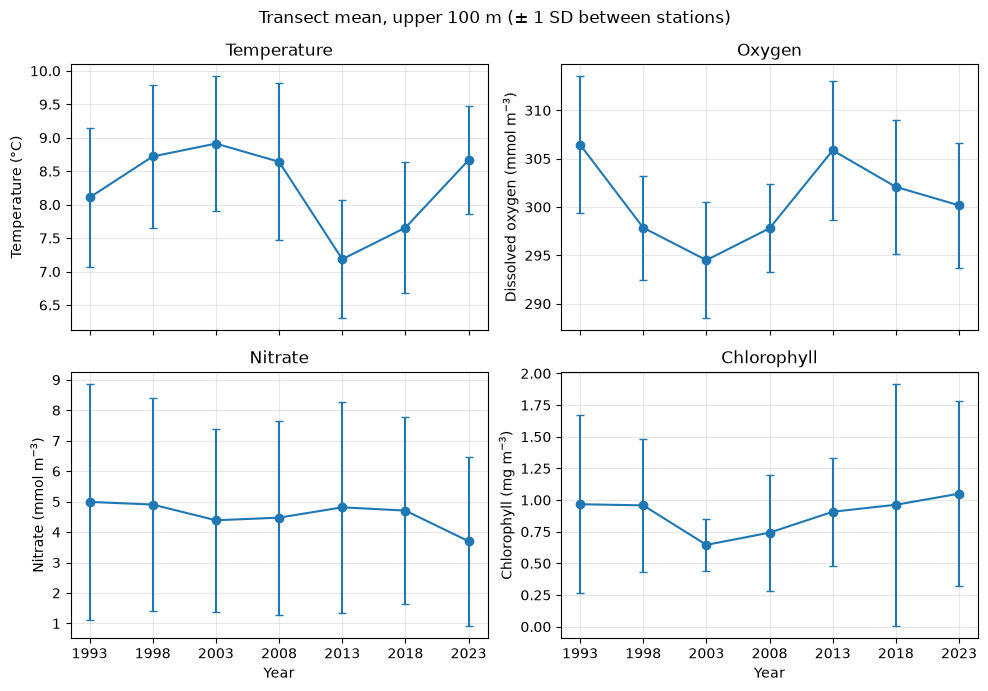

In [8]:
# Figure: time series of the transect mean (upper layer)
# Each point = mean over all stations
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for ax, var in zip(axes.flat, VAR_NAMES):
    M = matrices[var]
    ax.errorbar(
        years,
        np.nanmean(M, axis=1),
        yerr=np.nanstd(M, axis=1),
        marker="o",
        capsize=3,
        color="tab:blue",
    )
    ax.set_ylabel(VARIABLES[var]["label"])
    ax.set_title(var.capitalize())
    ax.grid(alpha=0.3)
    ax.set_xticks(years)
for ax in axes[1]:
    ax.set_xlabel("Year")
fig.suptitle(f"Transect mean, upper {UPPER_DEPTH} m (± 1 SD between stations)")
fig.tight_layout()

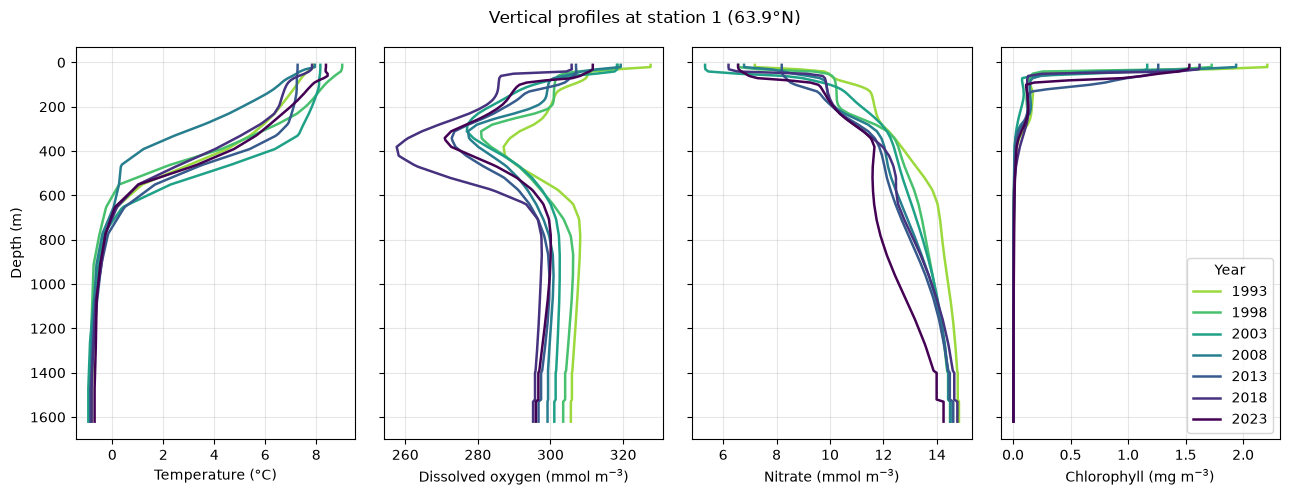

In [6]:
# Figure: vertical profiles at one station
# can change the station number and max depth in the beginning block of the notebook
cmap_years = plt.cm.viridis_r

# start at 0.15 instead of 0, so the lightest line is still visible on a white background
profile_colors = dict(zip(years, cmap_years(np.linspace(0.15, 1.0, len(years)))))

fig, axes = plt.subplots(1, 4, figsize=(13, 5), sharey=True)
for ax, var in zip(axes, VAR_NAMES):
    for year in years:
        cast = (
            data.filter(
                (pl.col("year") == year) & (pl.col("station") == PROFILE_STATION)
            )
            .sort("depth")
            .drop_nulls(var)
        )
        ax.plot(
            cast[var], cast["depth"], color=profile_colors[year], lw=1.8, label=year
        )
    ax.set_xlabel(VARIABLES[var]["label"])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Depth (m)")
axes[0].invert_yaxis()  # surface at the top
if PROFILE_MAX_DEPTH is not None:
    axes[0].set_ylim(PROFILE_MAX_DEPTH, 0)
axes[-1].legend(title="Year", loc="lower right")
lat_here = station_lat[PROFILE_STATION - 1]
fig.suptitle(f"Vertical profiles at station {PROFILE_STATION} ({lat_here:.1f}°N)")
fig.tight_layout()

10 stations, transect length 1279 km


Text(0.5, 1.03, 'Temperature (°C), May 1993')

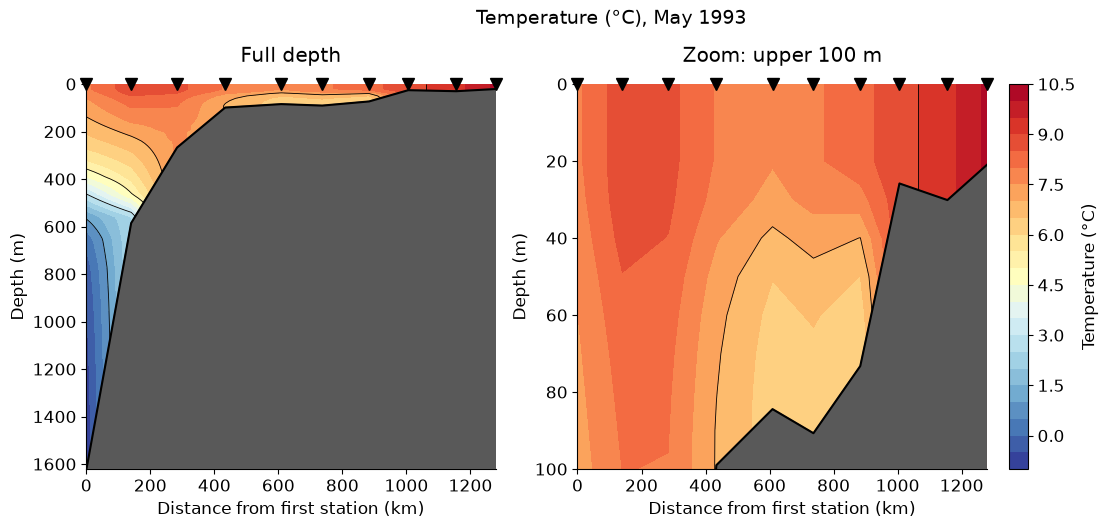

In [ ]:
# Creating a transect section (for temperature)
# in the graph, the observations along the triangles are actual station measurements, the rest is interpolated between the stations. The grey area is the sea floor.
# data is interpolated vertically onto a depth grid, and horizonatally between stations.
file = "/Users/4926196/Downloads/VSC/Oceans of the Future_BSc UU/Expeditions/1993/results/ctd.parquet"  # path to your CTD file
variable = (
    "temperature"  # column to plot: "o2", "temperature", "salinity", "no3", "chl", ...
)
title = "May 1993"
zoom_depth = 100  # depth (m) shown in the zoomed section
# ------------------------------------------

# label + colour map for each variable
info = {
    "o2": ("Dissolved oxygen (mmol m$^{-3}$)", "YlGnBu"),
    "temperature": ("Temperature (°C)", "RdYlBu_r"),
    "salinity": ("Salinity (psu)", "viridis"),
    "no3": ("Nitrate (mmol m$^{-3}$)", "YlOrBr"),
    "chl": ("Chlorophyll (mg m$^{-3}$)", "YlGn"),
}
label, cmap = info.get(variable, (variable, "viridis"))

plt.rcParams.update(
    {"font.size": 12, "axes.spines.top": False, "axes.spines.right": False}
)

# Loading the data using Polars (faster than Parcels read_particlefile for large CTD files)
df = pl.read_parquet(file)

df = df.filter(pl.col("raising") == 0)  # downcast only
df = df.with_columns((-pl.col("z")).alias("depth"))  # depth as a positive number
df = (
    df.filter(pl.col(variable) > 0) if variable == "o2" else df
)  # remove missing oxygen values

# one row per station: where it is and how deep the sea floor is
stations = (
    df.group_by("particle_id")
    .agg(
        pl.col("x").mean().alias("lon"),
        pl.col("y").mean().alias("lat"),
        (-pl.col("max_depth").first()).alias("seafloor"),
        pl.col("t").min().alias("t0"),
    )
    .sort("t0")
)


# distance from the first station (km), using the haversine formula for distances on a sphere
def distance_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))


lon, lat = stations["lon"].to_numpy(), stations["lat"].to_numpy()
dist = np.array([distance_km(lon[0], lat[0], lo, la) for lo, la in zip(lon, lat)])
seafloor = stations["seafloor"].to_numpy()
ids = stations["particle_id"].to_numpy()

# put every station on the same depth axis (every 10 m) so we can make a section.
# Between the last measurement and the sea floor we simply repeat the last value (the grey sea floor is drawn on top).
depth_axis = np.arange(0, df["depth"].max() + 10, 10)
section = np.full((len(ids), len(depth_axis)), np.nan)
for i, pid in enumerate(ids):
    c = df.filter(pl.col("particle_id") == pid).sort("depth")
    section[i] = np.interp(
        depth_axis, c["depth"], c[variable]
    )  # outside the cast: repeat first/last value

print(f"{len(ids)} stations, transect length {dist[-1]:.0f} km")


# plotting the transect section
def draw_section(ax, max_depth, label_lines=True):
    step = 0.5  # colour step; contour line every 4th step
    levels = np.arange(
        np.floor(np.nanmin(section) / step) * step, np.nanmax(section) + step, step
    )
    filled = ax.contourf(dist, depth_axis, section.T, levels=levels, cmap=cmap)
    lines = ax.contour(
        dist, depth_axis, section.T, levels=levels[::4], colors="k", linewidths=0.6
    )
    if label_lines:
        ax.clabel(lines, fmt="%.0f", fontsize=8)

    # grey sea floor
    ax.fill_between(dist, seafloor, max_depth * 2, color="0.35", zorder=3)
    ax.plot(dist, seafloor, color="k", lw=1.5, zorder=4)

    # stations
    ax.plot(dist, np.zeros_like(dist), "kv", ms=9, clip_on=False, zorder=5)
    ax.set_ylim(max_depth, 0)
    ax.set_xlabel("Distance from first station (km)")
    ax.set_ylabel("Depth (m)")
    return filled


fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1]})
draw_section(axes[0], df["depth"].max(), label_lines=False)
axes[0].set_title("Full depth", pad=16)
filled = draw_section(axes[1], zoom_depth)
axes[1].set_title(f"Zoom: upper {zoom_depth} m", pad=16)
fig.colorbar(filled, ax=axes, label=label, pad=0.02)
fig.suptitle(f"{label}, {title}", fontsize=14, y=1.03)